# Homework 6

Name: Hao Huang  
GitHub: Arvinhh7  
USC ID: 8055359762

## 1. Tree-Based Methods
### (a) Load the APS data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, accuracy_score, recall_score, precision_score
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
SEED = 552
DATA = Path('data')
train = pd.read_csv(DATA/'aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv(DATA/'aps_failure_test_set.csv', skiprows=20, na_values='na')
X = train.drop(columns='class').astype('float32')
Xt = test.drop(columns='class').astype('float32')
y = (train['class']=='pos').astype(int).to_numpy()
yt = (test['class']=='pos').astype(int).to_numpy()
assert X.columns.equals(Xt.columns) and X.shape == (60000,170)
print('Training:', train.shape, '| Test:', test.shape)
display(train.head())
train.info()
display(X.describe())

Training: (60000, 171) | Test: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 171 entries, class to eg_000
dtypes: float64(169), int64(1), str(1)
memory usage: 78.4 MB


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
count,6.000000e+04,13671.000000,5.666500e+04,4.513900e+04,57500.000000,57500.000000,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,...,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,59329.00,5.932900e+04,5.932900e+04,5.932900e+04,57276.000000,57277.000000
mean,5.933650e+04,0.713189,3.560142e+08,1.906207e+05,6.819130,11.006818,2.216364e+02,9.757223e+02,8.606014e+03,8.859128e+04,...,4.454897e+05,2.111264e+05,4.457343e+05,3.939462e+05,333058.25,3.462714e+05,1.387300e+05,8.388915e+03,0.090579,0.212756
std,1.454300e+05,3.478962,7.948749e+08,4.040441e+07,161.543381,209.792603,2.047846e+04,3.420053e+04,1.503220e+05,7.617312e+05,...,1.155540e+06,5.433188e+05,1.168314e+06,1.121044e+06,1069159.75,1.728056e+06,4.495101e+05,4.747043e+04,4.368855,8.830641
min,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,8.340000e+02,0.000000,1.600000e+01,2.400000e+01,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,2.936000e+03,1.166000e+03,2.700000e+03,3.584000e+03,512.00,1.100000e+02,0.000000e+00,0.000000e+00,0.000000,0.000000
50%,3.077600e+04,0.000000,1.520000e+02,1.260000e+02,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,2.337960e+05,1.120860e+05,2.215180e+05,1.899880e+05,92432.00,4.109800e+04,3.812000e+03,0.000000e+00,0.000000,0.000000
75%,4.866800e+04,0.000000,9.640000e+02,4.300000e+02,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,4.383960e+05,2.182320e+05,4.666140e+05,4.032220e+05,275094.00,1.678140e+05,1.397240e+05,2.028000e+03,0.000000,0.000000
max,2.746564e+06,204.000000,2.130707e+09,8.584298e+09,21050.000000,20070.000000,3.376892e+06,4.109372e+06,1.055286e+07,6.340207e+07,...,7.793393e+07,3.775839e+07,9.715238e+07,5.743524e+07,31607814.00,1.195801e+08,1.926740e+07,3.810078e+06,482.000000,1146.000000


### (b)(i) Missing values
Missing values can be handled by dropping incomplete rows, mean/median/mode imputation, KNN, or iterative imputation. I use median imputation because the features are skewed and dropping rows would lose data. Medians are fitted on the training data only, separately within each CV fold. Entirely missing columns are filled with zero.

In [2]:
missing = pd.DataFrame({'train_missing': X.isna().sum(), 'test_missing': Xt.isna().sum()})
display(missing.sort_values('train_missing', ascending=False))
print('Missing training entries:', int(X.isna().sum().sum()))
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
Xi = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
Xti = pd.DataFrame(imputer.transform(Xt), columns=X.columns)
assert not Xi.isna().any().any() and not Xti.isna().any().any()
display(Xi.head())

,train_missing,test_missing
br_000,49264,13129
bq_000,48722,12981
bp_000,47740,12721
bo_000,46333,12376
ab_000,46329,12363
...,...,...
ck_000,338,86
ci_000,338,86
cj_000,338,86
bt_000,167,28


Missing training entries: 850015


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,76698.0,0.0,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,33058.0,0.0,0.000000e+00,126.0,0.0,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,41040.0,0.0,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,12.0,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,60874.0,0.0,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b)(ii) Coefficients of variation
For each feature, I calculate $CV=s/\bar{x}$ using the sample standard deviation ($ddof=1$) on the imputed training set. A zero mean gives an undefined CV and is excluded from the ranking.

In [3]:
cv_features = pd.DataFrame({'mean': Xi.mean(), 'sample_sd': Xi.std(ddof=1)})
cv_features['CV'] = cv_features['sample_sd']/cv_features['mean'].replace(0,np.nan)
with pd.option_context('display.max_rows', 180):
    display(cv_features)
top = cv_features['CV'].dropna().nlargest(int(np.sqrt(X.shape[1]))).index.tolist()
print('Selected', len(top), 'features:', top)

,mean,sample_sd,CV
aa_000,5.933650e+04,1.454300e+05,2.450938
ab_000,1.625000e-01,1.687318e+00,10.383494
ac_000,3.362258e+08,7.767626e+08,2.310241
ad_000,1.434383e+05,3.504525e+07,244.322815
ae_000,6.535000e+00,1.581479e+02,24.200136
af_000,1.054820e+01,2.053871e+02,19.471296
ag_000,2.191577e+02,2.036364e+04,92.917755
ag_001,9.648105e+02,3.400891e+04,35.249313
ag_002,8.509771e+03,1.494818e+05,17.565908
ag_003,8.760054e+04,7.575171e+05,8.647402


Selected 13 features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


### (b)(iii) Correlation matrix

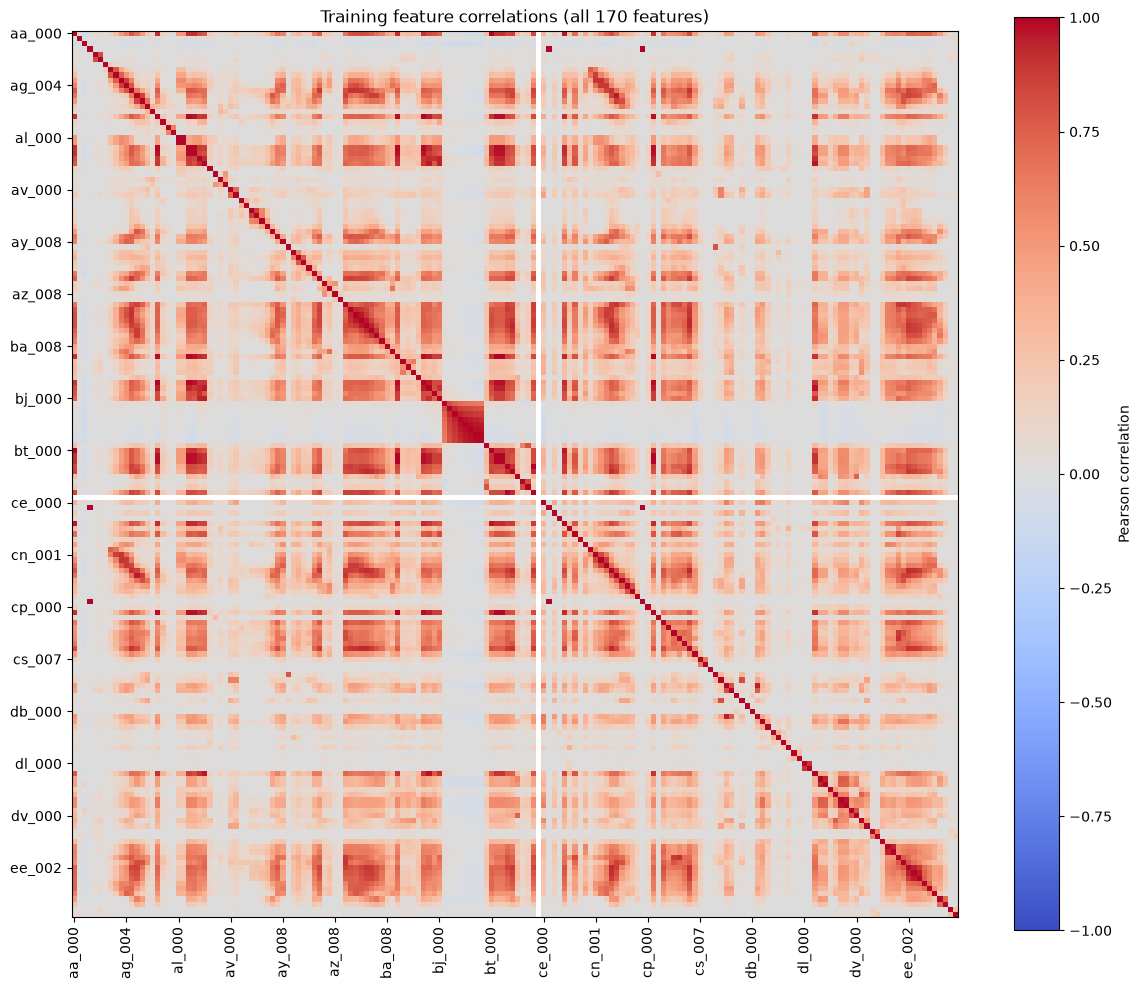

In [4]:
fig, ax = plt.subplots(figsize=(12,10))
im = ax.imshow(Xi.corr(), cmap='coolwarm', vmin=-1, vmax=1)
idx = np.arange(0,170,10)
ax.set_xticks(idx, Xi.columns[idx], rotation=90); ax.set_yticks(idx,Xi.columns[idx])
ax.set_title('Training feature correlations (all 170 features)')
fig.colorbar(im,ax=ax,label='Pearson correlation'); plt.tight_layout(); plt.show()

### (b)(iv) Scatterplots and boxplots
I select the 13 features with the highest CV. The scatterplots use a fixed sample of 2,000 negative and 1,000 positive cases; the boxplots use the full training set. Both use $\log(1+x)$ for readability. The models still use all 170 features without this transformation.

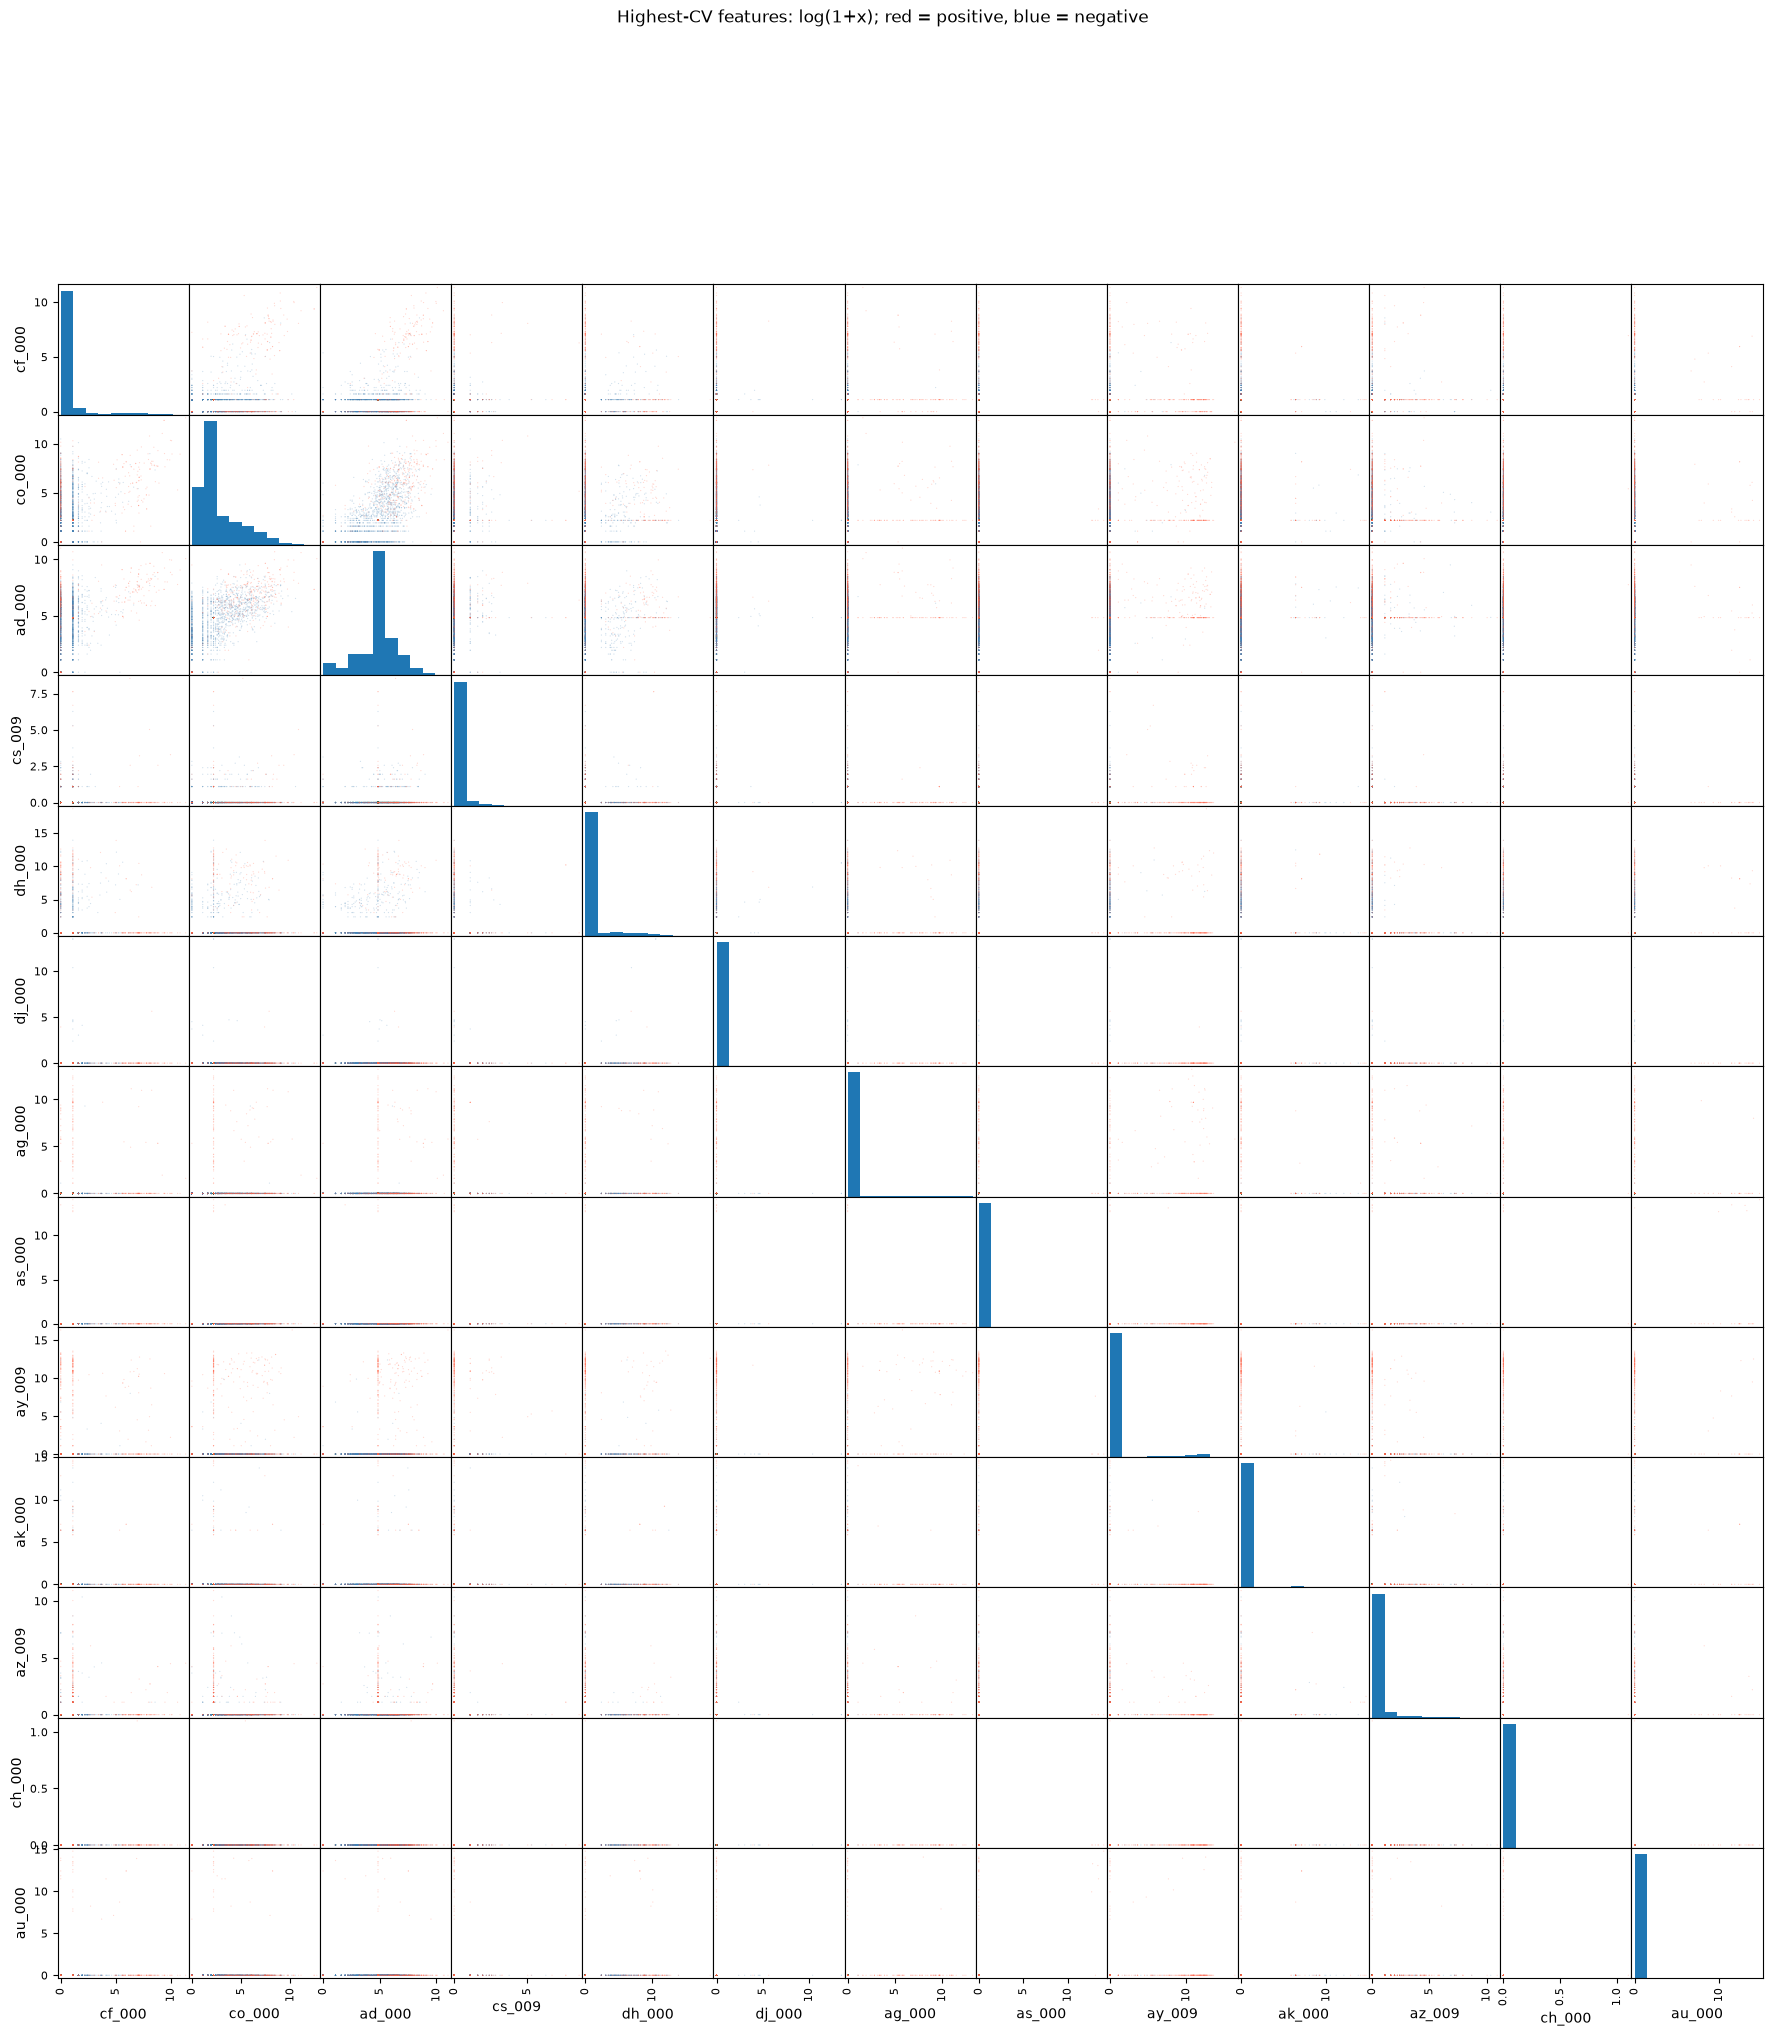

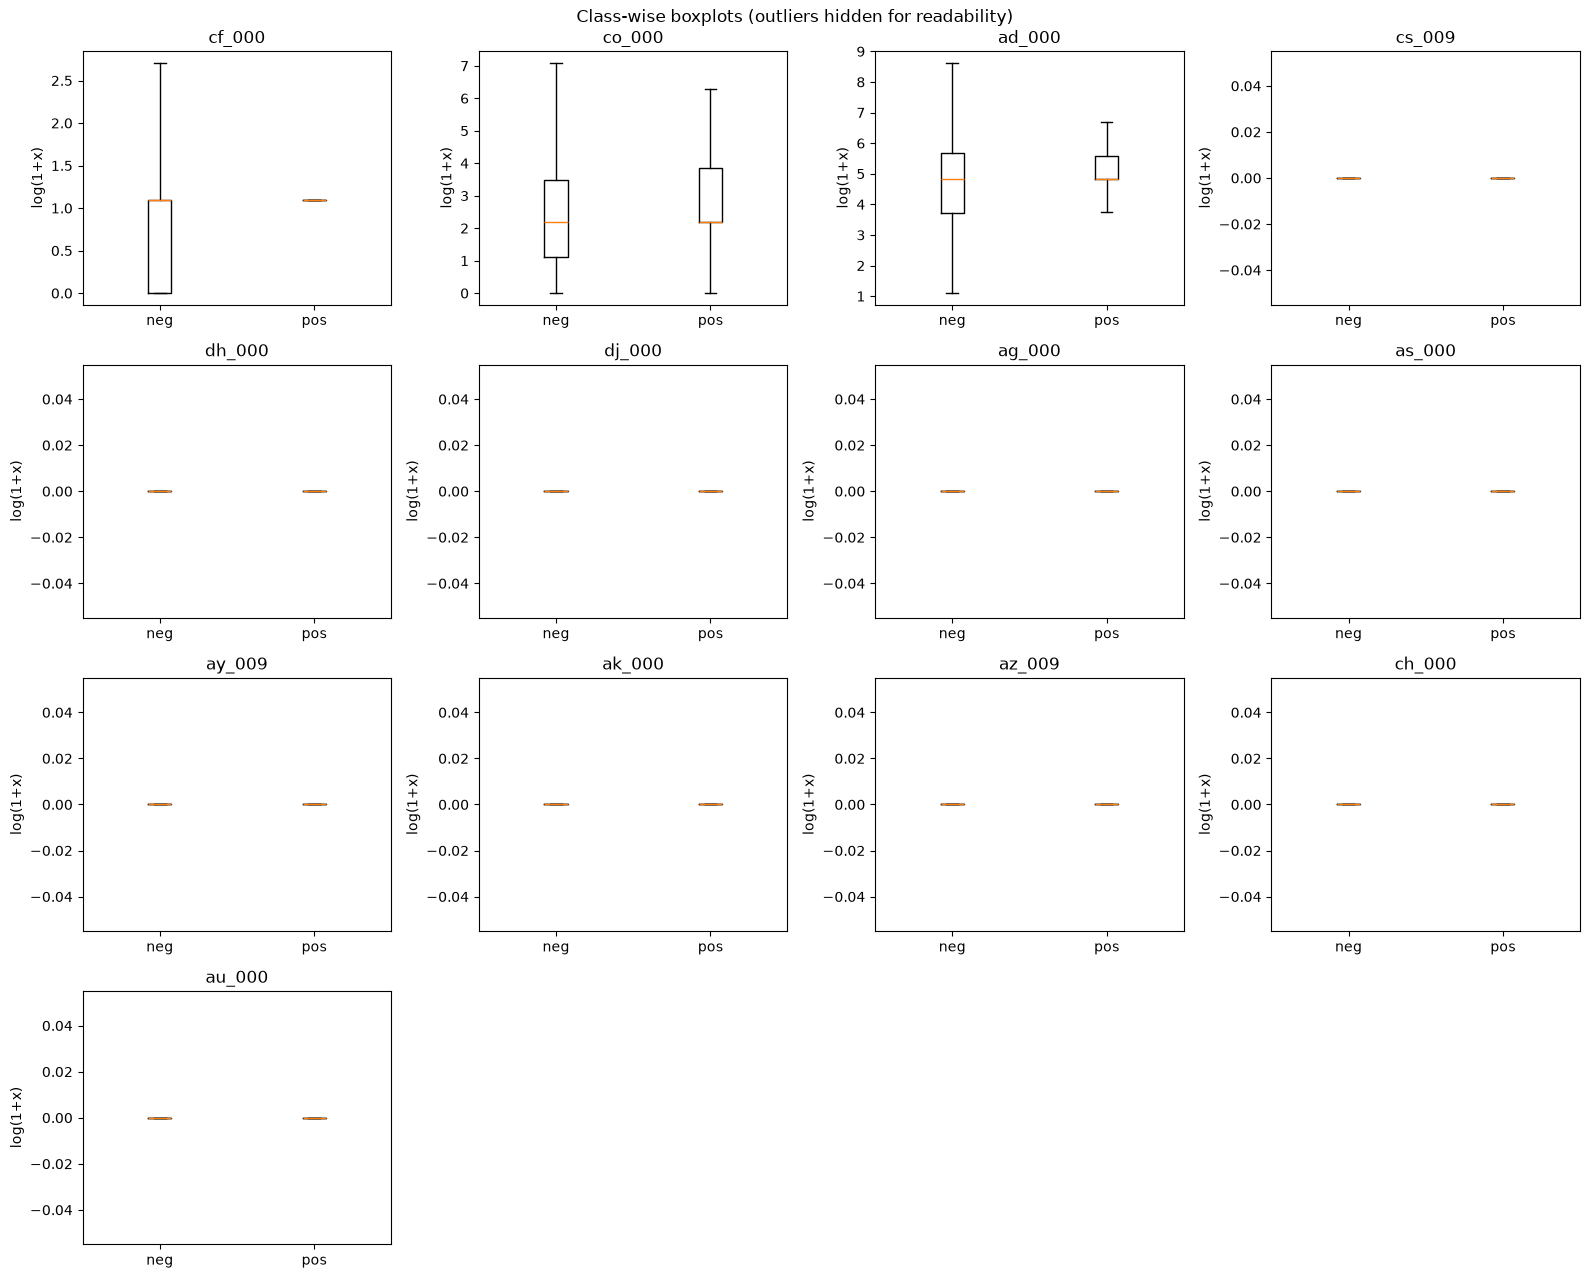

In [5]:
rng = np.random.default_rng(SEED)
visual_idx = np.r_[rng.choice(np.flatnonzero(y==0),2000,replace=False), np.flatnonzero(y==1)]
assert Xi[top].min().min() >= 0
visual = np.log1p(Xi.loc[visual_idx,top])
from pandas.plotting import scatter_matrix
axes = scatter_matrix(visual, figsize=(22,22), diagonal='hist',
                      c=np.where(y[visual_idx]==1,'tomato','steelblue'), alpha=.25, s=3)
plt.suptitle('Highest-CV features: log(1+x); red = positive, blue = negative',y=1.005)
plt.show()
fig, axes = plt.subplots(4,4,figsize=(16,13))
for ax,col in zip(axes.flat,top):
    ax.boxplot([np.log1p(Xi.loc[y==0,col]),np.log1p(Xi.loc[y==1,col])],
               tick_labels=['neg','pos'], showfliers=False)
    ax.set_title(col); ax.set_ylabel('log(1+x)')
for ax in axes.flat[len(top):]: ax.axis('off')
plt.suptitle('Class-wise boxplots (outliers hidden for readability)')
plt.tight_layout(); plt.show()

High CV means high relative variability, not necessarily a useful predictor. The plots show overlap and possible class differences, but they are not enough to conclude that a feature is statistically significant.

### (b)(v) Class imbalance

In [6]:
counts = pd.DataFrame({'training': np.bincount(y), 'test': np.bincount(yt)}, index=['neg','pos'])
display(counts)
print(f'Training positive rate: {y.mean():.3%}; negative-to-positive ratio: {(y==0).sum()/(y==1).sum():.1f}:1')
print(f'Always-negative test error: {yt.mean():.3%}')

,training,test
neg,59000,15625
pos,1000,375


Training positive rate: 1.667%; negative-to-positive ratio: 59.0:1
Always-negative test error: 2.344%


There are 59 negative cases for each positive case in training. Accuracy alone can hide missed failures, so I also compare positive-class recall and ROC AUC. All classifications below use a fixed probability threshold of 0.5.

In [7]:
results = []
def evaluate(name, model, train_input, test_input, cv_error=np.nan, oob_error=np.nan):
    probabilities = [model.predict_proba(train_input)[:,1],model.predict_proba(test_input)[:,1]]
    fig, axes = plt.subplots(1,3,figsize=(15,4))
    row = {'Model':name, 'CV error':cv_error, 'OOB error':oob_error}
    for j,(label,truth,p) in enumerate(zip(['Train','Test'],[y,yt],probabilities)):
        pred=(p>=.5).astype(int)
        ConfusionMatrixDisplay(confusion_matrix(truth,pred,labels=[0,1]),display_labels=['neg','pos']).plot(ax=axes[j],colorbar=False)
        axes[j].set_title(name+' — '+label)
        auc=roc_auc_score(truth,p)
        fpr,tpr,_=roc_curve(truth,p)
        axes[2].plot(fpr,tpr,label=f'{label} AUC={auc:.4f}')
        row[label+' error']=1-accuracy_score(truth,pred)
        row[label+' AUC']=auc
        row[label+' recall']=recall_score(truth,pred)
        row[label+' precision']=precision_score(truth,pred,zero_division=0)
    axes[2].plot([0,1],[0,1],'k--'); axes[2].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC')
    axes[2].legend(); plt.tight_layout(); plt.show()
    results.append(row); display(pd.DataFrame([row]).set_index('Model'))
    return row

### (c) Random forest without compensation
I use 100 bootstrap trees and the default square-root feature subset. OOB predictions use trees that did not sample a given observation. The OOB estimate reuses the training-set median imputation, so it is not completely independent of preprocessing.

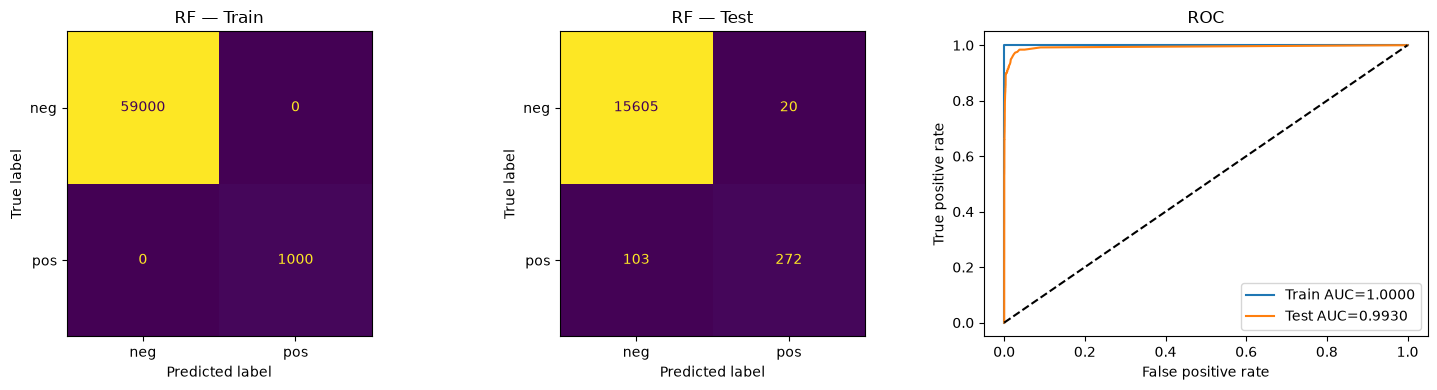

,CV error,OOB error,Train error,Train AUC,Train recall,Train precision,Test error,Test AUC,Test recall,Test precision
Model,,,,,,,,,,
RF,NaN,0.00615,0.0,1.0,1.0,1.0,0.007687,0.99304,0.725333,0.931507


OOB error = 0.0061; test error = 0.0077.


In [8]:
rf = RandomForestClassifier(n_estimators=100, max_features='sqrt', oob_score=True, n_jobs=1, random_state=SEED)
rf.fit(Xi,y)
base_rf = evaluate('RF',rf,Xi,Xti,oob_error=1-rf.oob_score_)
print(f"OOB error = {base_rf['OOB error']:.4f}; test error = {base_rf['Test error']:.4f}.")

### (d) Random forest with class weighting
Class imbalance can be addressed with class weights, undersampling, oversampling, or threshold adjustment. I use `balanced_subsample`, which weights classes inversely to their frequency in each bootstrap sample.

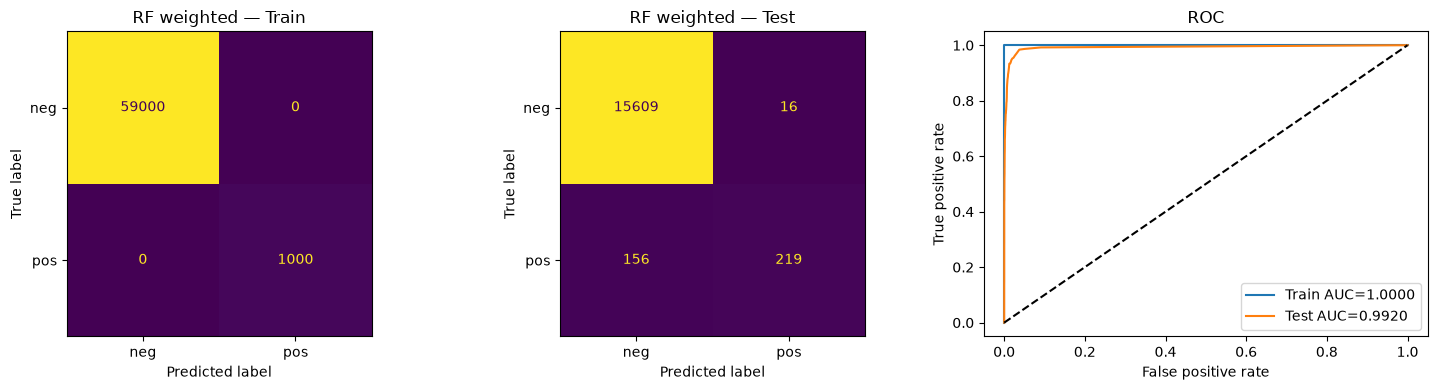

,CV error,OOB error,Train error,Train AUC,Train recall,Train precision,Test error,Test AUC,Test recall,Test precision
Model,,,,,,,,,,
RF weighted,NaN,0.007817,0.0,1.0,1.0,1.0,0.01075,0.992047,0.584,0.931915


Weighting changes test error from 0.0077 to 0.0108, recall from 0.7253 to 0.5840, and AUC from 0.9930 to 0.9920.
Weighted OOB error: 0.0078; test error: 0.0108.


In [9]:
rf_balanced = RandomForestClassifier(n_estimators=100, max_features='sqrt', class_weight='balanced_subsample', oob_score=True, n_jobs=1, random_state=SEED)
rf_balanced.fit(Xi,y)
bal_rf = evaluate('RF weighted',rf_balanced,Xi,Xti,oob_error=1-rf_balanced.oob_score_)
print(f"Weighting changes test error from {base_rf['Test error']:.4f} to {bal_rf['Test error']:.4f}, recall from {base_rf['Test recall']:.4f} to {bal_rf['Test recall']:.4f}, and AUC from {base_rf['Test AUC']:.4f} to {bal_rf['Test AUC']:.4f}.")
print(f"Weighted OOB error: {bal_rf['OOB error']:.4f}; test error: {bal_rf['Test error']:.4f}.")

### (e) XGBoost and L1 regularization
I fit both `gblinear` (L1-regularized logistic regression) and `gbtree` (L1-regularized boosted trees). XGBoost does not fit logistic regression at each tree node, so these are not oblique model trees.

I choose alpha using five-fold stratified CV, minimizing misclassification error and using AUC to break ties. Each fold fits its own imputer and scaler. Part (e) uses no class weighting or resampling. Both boosters use 100 rounds, with learning rates of 0.01 for `gblinear` and 0.1 for `gbtree`. The test set is held out. Since the same CV results select alpha, the reported CV error may be slightly optimistic.

Fold 1/5 complete


Fold 2/5 complete


Fold 3/5 complete


Fold 4/5 complete


Fold 5/5 complete


,booster,alpha,cv_error,sd_error,cv_AUC
0,gblinear,0.0000,0.010833,0.001046,0.976685
1,gblinear,0.0001,0.010833,0.001046,0.977055
2,gblinear,0.0010,0.011300,0.001201,0.980622
3,gblinear,0.0100,0.014483,0.001009,0.978552
4,gblinear,0.1000,0.016667,0.000000,0.500000
5,gbtree,0.0000,0.006983,0.000794,0.987995
6,gbtree,0.1000,0.007050,0.000666,0.988651
7,gbtree,1.0000,0.007300,0.000622,0.988890
8,gbtree,10.0000,0.008083,0.000806,0.988671


gblinear: selected alpha = 0.0001


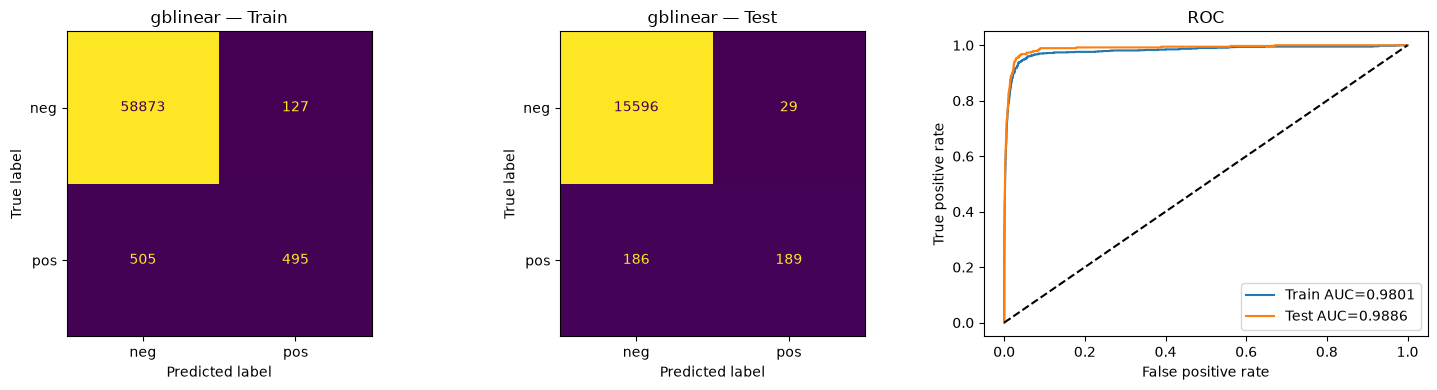

,CV error,OOB error,Train error,Train AUC,Train recall,Train precision,Test error,Test AUC,Test recall,Test precision
Model,,,,,,,,,,
gblinear,0.010833,NaN,0.010533,0.980071,0.495,0.79582,0.013437,0.988642,0.504,0.866972


gbtree: selected alpha = 0


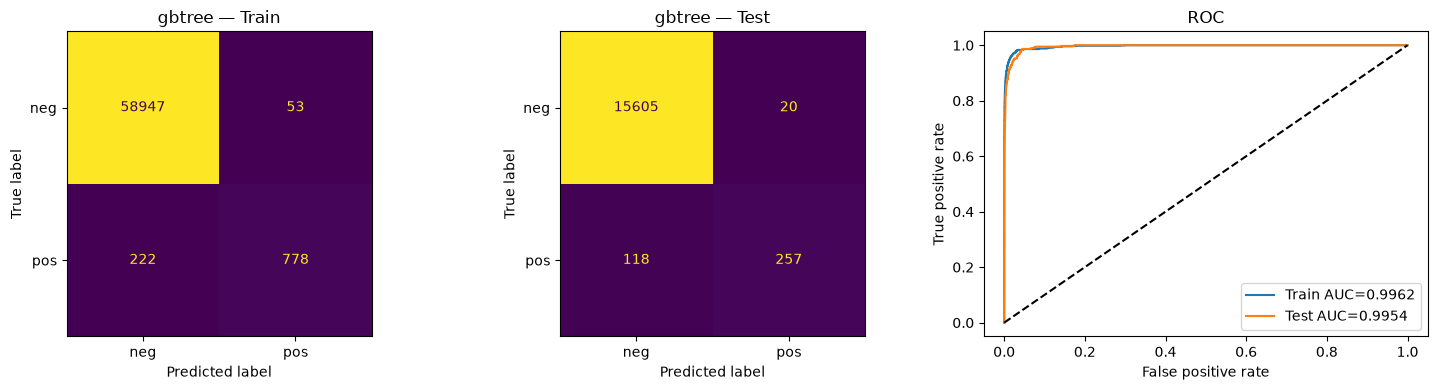

,CV error,OOB error,Train error,Train AUC,Train recall,Train precision,Test error,Test AUC,Test recall,Test precision
Model,,,,,,,,,,
gbtree,0.006983,NaN,0.004583,0.99625,0.778,0.936221,0.008625,0.995385,0.685333,0.927798


In [10]:
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X,y))
alpha_grids = {'gblinear':[0, .0001, .001, .01, .1], 'gbtree':[0, .1, 1, 10]}
def make_xgb(kind, alpha):
    common = dict(booster=kind, objective='binary:logistic', reg_alpha=alpha,
                  n_estimators=100, learning_rate=.1, n_jobs=1, random_state=SEED,
                  verbosity=0, eval_metric='logloss')
    if kind=='gblinear':
        common.update(updater='coord_descent',feature_selector='cyclic',reg_lambda=0,learning_rate=.01)
    else:
        common.update(tree_method='hist',max_depth=3,reg_lambda=1)
    return XGBClassifier(**common)
def tune_xgb(use_smote=False):
    rows=[]
    for fold,(tr,va) in enumerate(folds,1):
        imp=SimpleImputer(strategy='median',keep_empty_features=True)
        scaler=StandardScaler()
        a=scaler.fit_transform(imp.fit_transform(X.iloc[tr]))
        b=scaler.transform(imp.transform(X.iloc[va]))
        labels=y[tr]
        if use_smote:
            a,labels=SMOTE(random_state=SEED+fold).fit_resample(a,labels)
        for kind,grid in alpha_grids.items():
            for alpha in grid:
                model=make_xgb(kind,alpha).fit(a,labels)
                p=model.predict_proba(b)[:,1]
                rows.append({'booster':kind,'alpha':alpha,'fold':fold,
                             'error':1-accuracy_score(y[va],p>=.5), 'AUC':roc_auc_score(y[va],p)})
        print(f'Fold {fold}/5 complete',flush=True)
    summary=pd.DataFrame(rows).groupby(['booster','alpha']).agg(
        cv_error=('error','mean'),sd_error=('error','std'),cv_AUC=('AUC','mean')).reset_index()
    display(summary)
    return summary
cv_plain=tune_xgb(False)
scaler=StandardScaler()
Xs=scaler.fit_transform(Xi); Xts=scaler.transform(Xti)
def fit_selected(summary,use_smote=False):
    a,labels=Xs,y
    if use_smote:
        a,labels=SMOTE(random_state=SEED).fit_resample(Xs,y)
        print('Full resampled training shape:',a.shape,'; class counts:',np.bincount(labels))
    for kind in alpha_grids:
        best=summary[summary.booster==kind].sort_values(['cv_error','cv_AUC','alpha'],ascending=[True,False,True]).iloc[0]
        print(f"{kind}: selected alpha = {best.alpha:g}")
        model=make_xgb(kind,float(best.alpha)).fit(a,labels)
        evaluate(kind+(' + SMOTE' if use_smote else ''),model,Xs,Xts,cv_error=float(best.cv_error))
fit_selected(cv_plain)

### (f) SMOTE
SMOTE creates minority-class samples between neighboring minority observations. I apply it after imputation and scaling within each training fold. Validation and test data are not resampled. The final training set has 118,000 rows, with 59,000 in each class. Training metrics are measured on the original 60,000 observations.

Fold 1/5 complete


Fold 2/5 complete


Fold 3/5 complete


Fold 4/5 complete


Fold 5/5 complete


,booster,alpha,cv_error,sd_error,cv_AUC
0,gblinear,0.0000,0.034983,0.002024,0.981683
1,gblinear,0.0001,0.035267,0.001917,0.981748
2,gblinear,0.0010,0.037217,0.001743,0.981892
3,gblinear,0.0100,0.046783,0.001348,0.980060
4,gblinear,0.1000,0.045700,0.001089,0.976485
5,gbtree,0.0000,0.022150,0.001282,0.986320
6,gbtree,0.1000,0.021933,0.001006,0.986412
7,gbtree,1.0000,0.022400,0.001286,0.986502
8,gbtree,10.0000,0.023033,0.001524,0.986348


Full resampled training shape: (118000, 170) ; class counts: [59000 59000]
gblinear: selected alpha = 0


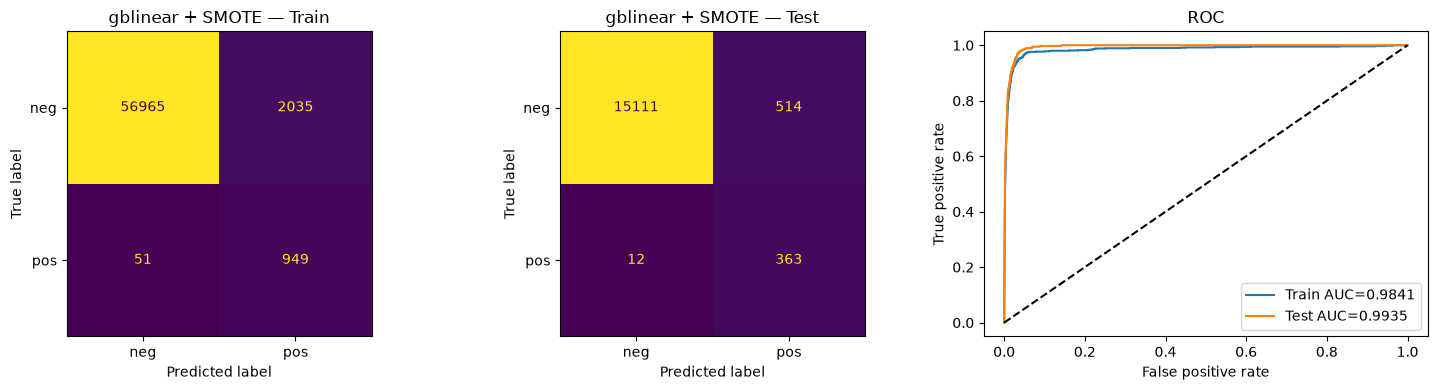

,CV error,OOB error,Train error,Train AUC,Train recall,Train precision,Test error,Test AUC,Test recall,Test precision
Model,,,,,,,,,,
gblinear + SMOTE,0.034983,NaN,0.034767,0.9841,0.949,0.318029,0.032875,0.993455,0.968,0.413911


gbtree: selected alpha = 0.1


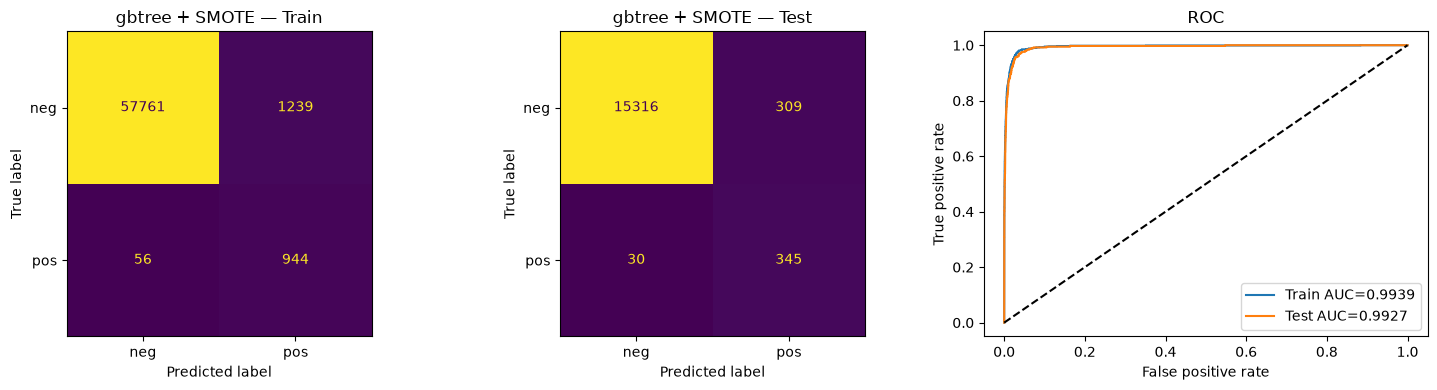

,CV error,OOB error,Train error,Train AUC,Train recall,Train precision,Test error,Test AUC,Test recall,Test precision
Model,,,,,,,,,,
gbtree + SMOTE,0.021933,NaN,0.021583,0.993913,0.944,0.432432,0.021188,0.992672,0.92,0.527523


,CV error,OOB error,Train error,Train AUC,Train recall,Train precision,Test error,Test AUC,Test recall,Test precision
Model,,,,,,,,,,
RF,NaN,0.006150,0.000000,1.000000,1.000,1.000000,0.007687,0.993040,0.725333,0.931507
RF weighted,NaN,0.007817,0.000000,1.000000,1.000,1.000000,0.010750,0.992047,0.584000,0.931915
gblinear,0.010833,NaN,0.010533,0.980071,0.495,0.795820,0.013437,0.988642,0.504000,0.866972
gbtree,0.006983,NaN,0.004583,0.996250,0.778,0.936221,0.008625,0.995385,0.685333,0.927798
gblinear + SMOTE,0.034983,NaN,0.034767,0.984100,0.949,0.318029,0.032875,0.993455,0.968000,0.413911
gbtree + SMOTE,0.021933,NaN,0.021583,0.993913,0.944,0.432432,0.021188,0.992672,0.920000,0.527523


**gblinear:** SMOTE changes test error from 0.0134 to 0.0329, positive recall from 0.5040 to 0.9680, and AUC from 0.9886 to 0.9935. Without SMOTE, CV/test errors are 0.0108/0.0134; with SMOTE they are 0.0350/0.0329.

**gbtree:** SMOTE changes test error from 0.0086 to 0.0212, positive recall from 0.6853 to 0.9200, and AUC from 0.9954 to 0.9927. Without SMOTE, CV/test errors are 0.0070/0.0086; with SMOTE they are 0.0219/0.0212.

In [11]:
cv_smote=tune_xgb(True)
fit_selected(cv_smote,True)
comparison=pd.DataFrame(results).set_index('Model')
display(comparison)
for kind in alpha_grids:
    a,b=comparison.loc[kind],comparison.loc[kind+' + SMOTE']
    display(Markdown(f"**{kind}:** SMOTE changes test error from {a['Test error']:.4f} to {b['Test error']:.4f}, positive recall from {a['Test recall']:.4f} to {b['Test recall']:.4f}, and AUC from {a['Test AUC']:.4f} to {b['Test AUC']:.4f}. Without SMOTE, CV/test errors are {a['CV error']:.4f}/{a['Test error']:.4f}; with SMOTE they are {b['CV error']:.4f}/{b['Test error']:.4f}."))

SMOTE increases recall but also creates more false positives at the 0.5 threshold. For the linear booster, test recall rises from 0.504 to 0.968, while test error rises from 0.0134 to 0.0329. For the tree booster, recall rises from 0.685 to 0.920, while error rises from 0.0086 to 0.0212. Thus, SMOTE detects more failures but does not reduce overall error here.

Class weighting also does not improve the random forest: test recall falls from 0.725 to 0.584, and error increases. Changing class weights does not guarantee better minority-class predictions.

## 2. ISLR 6.6.3 — Lasso constraint
The constraint is $\sum_j|\beta_j|\leq s$. At $s=0$, all slopes are zero. Increasing $s$ makes the feasible set larger and allows a more flexible fit.

| Part | Choice | Reason |
|---|---|---|
| (a) Training RSS | **iv: decreases** | The previous solution is still feasible, so the minimum RSS cannot increase. It can level off once the constraint is inactive. |
| (b) Test RSS | **ii: decreases, then increases** | Relaxing strong shrinkage first reduces underfitting; eventually extra variance can cause overfitting. This is the usual pattern, not a guarantee for every sample. |
| (c) Variance | **iii: increases** | A less constrained fit responds more strongly to changes in the training sample. |
| (d) Squared bias | **iv: decreases** | Less shrinkage allows a closer approximation to the underlying relationship. |
| (e) Irreducible error | **v: constant** | Changing the fitted model does not change the noise in the data-generating process. |

## 3. ISLR 6.6.5 — Identical predictors
Write $x_1=x_{11}=x_{12}$ and $x_2=x_{21}=x_{22}$. The centered data give $\hat\beta_0=0$. Let $A=x_1^2+x_2^2$ and $B=x_1y_1+x_2y_2$.

(a) The ridge problem is
$$\min_{\beta_1,\beta_2}\sum_{i=1}^2[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).$$
(b) Subtracting its two first-order equations gives $2\lambda(\beta_1-\beta_2)=0$. Thus, for $\lambda>0$, $\hat\beta_1=\hat\beta_2$. Substituting into either equation gives
$$\boxed{\hat\beta_1=\hat\beta_2=\frac{B}{2A+\lambda}}.$$
Equivalently, for a fixed sum $t$, the penalty is minimized at $\beta_1=\beta_2=t/2$. At $\lambda=0$, equality is not forced because the design is rank deficient.

(c) The lasso problem is
$$\min_{\beta_1,\beta_2}\sum_{i=1}^2[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).$$
(d) Assume $\lambda>0$. For a fixed sum $t$, the smallest penalty is $\lambda|t|$, attained whenever the coefficients have the same sign (including zero). For $A>0$, minimizing over $t$ gives
$$t^*=\frac{\operatorname{sign}(B)(|B|-\lambda/2)_+}{A}.$$
If $t^*\ne0$, every pair
$$\boxed{(\hat\beta_1,\hat\beta_2)=(a t^*,(1-a)t^*),\quad 0\leq a\leq1}$$
has the same fit and penalty. Thus one coefficient can be zero while the other takes the full sum, or they can split it. There are infinitely many solutions in this case. If shrinkage gives $t^*=0$ and $\lambda>0$, the unique solution is $(0,0)$, so nonuniqueness needs this qualification. If $A=0$ and $\lambda>0$, both estimates are also zero.

## 4. ISLR 8.4.5 — Combining ten trees
Majority vote: Six probabilities exceed 0.5 and four are below it. Therefore, six trees vote red and the predicted class is **red**.

Average probability:
$$\bar p=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=\frac{4.5}{10}=0.45.$$
Since $0.45<0.5$, the predicted class is **green**. Voting discards how confident each tree is, so the two methods can disagree.

## 5. ISLR 9.7.3 — Maximal margin classifier
**(a)** The points and class labels are plotted below.

**(b)–(c)** The nearest red boundary lies on $X_2=X_1$, and the nearest blue boundary lies on $X_2=X_1-1$. The line halfway between them is
$$\boxed{X_2=X_1-\tfrac12}.$$
Thus $\beta_0=1/2,\ \beta_1=-1,\ \beta_2=1$. Predict **red** when $1/2-X_1+X_2>0$ and **blue** otherwise. The facing convex-hull edges have perpendicular distance $1/\sqrt2$, so no separating line can have a minimum distance larger than half that gap. The midpoint line attains this bound.

**(d)** The margin on each side is
$$M=\frac{1/2}{\sqrt{(-1)^2+1^2}}=\boxed{\frac{1}{2\sqrt2}\approx0.3536}.$$
The full margin band has width $1/\sqrt2$. A unit-normal representation is $(\beta_0,\beta_1,\beta_2)=(1/(2\sqrt2),-1/\sqrt2,1/\sqrt2)$.

**(e)** The support vectors are observations **2, 3, 5, and 6**: $(2,2),(4,4),(2,1),(4,3)$.

**(f)** Observation 7, $(4,1)$, is well outside the margin: its distance to the decision line is $2.5/\sqrt2$. A sufficiently small movement leaves the supporting edges unchanged, so the optimal line stays the same.

**(g)** $X_2=X_1-0.25$ also separates the classes, but its minimum distance is $0.25/\sqrt2$, smaller than the optimal margin.

**(h)** Add a **blue** observation at $(3,3)$. It is the midpoint of the two red observations $(2,2)$ and $(4,4)$. A linear score positive at both endpoints must be positive at their midpoint, so strict linear separation is now impossible.

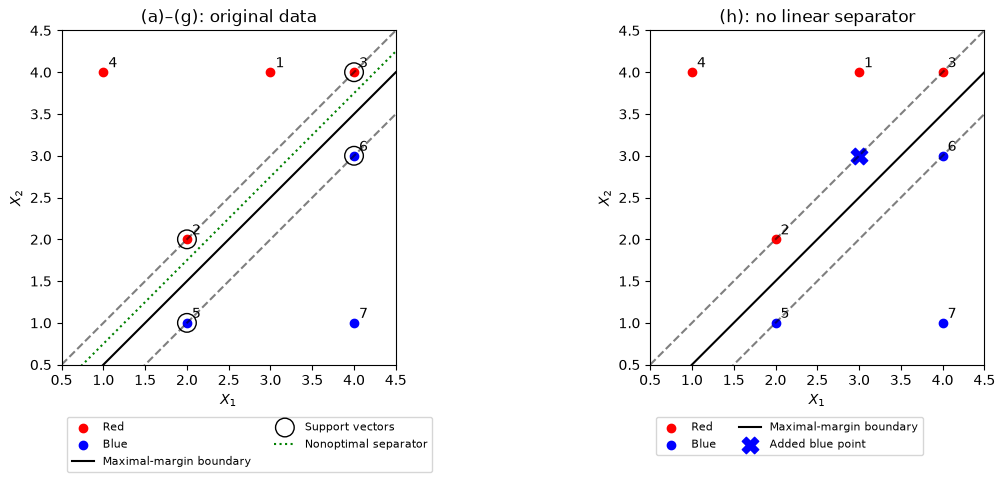

In [12]:
points=np.array([[3,4],[2,2],[4,4],[1,4],[2,1],[4,3],[4,1]])
fig,axes=plt.subplots(1,2,figsize=(12,5))
xx=np.linspace(.5,4.5,100)
for ax in axes:
    ax.scatter(points[:4,0],points[:4,1],c='red',label='Red')
    ax.scatter(points[4:,0],points[4:,1],c='blue',label='Blue')
    for i,(a,b) in enumerate(points,1): ax.annotate(str(i),(a+.06,b+.06))
    ax.plot(xx,xx-.5,'k-',label='Maximal-margin boundary')
    ax.plot(xx,xx,'k--',alpha=.5); ax.plot(xx,xx-1,'k--',alpha=.5)
    ax.set(xlim=(.5,4.5),ylim=(.5,4.5),xlabel='$X_1$',ylabel='$X_2$'); ax.set_aspect('equal')
axes[0].scatter(points[[1,2,4,5],0],points[[1,2,4,5],1],s=180,facecolors='none',edgecolors='black',label='Support vectors')
axes[0].plot(xx,xx-.25,':',color='green',label='Nonoptimal separator')
axes[0].set_title('(a)–(g): original data'); axes[0].legend(fontsize=8,loc='upper left',bbox_to_anchor=(0,-.14),ncol=2)
axes[1].scatter(3,3,c='blue',marker='X',s=140,label='Added blue point')
axes[1].set_title('(h): no linear separator'); axes[1].legend(fontsize=8,loc='upper left',bbox_to_anchor=(0,-.14),ncol=2)
plt.tight_layout(); plt.show()

## 6. Extra Practice
### ISLR 5.4.2 — Bootstrap inclusion
**(a)** The first draw misses observation $j$ with probability $(n-1)/n=1-1/n$.

**(b)** Sampling is with replacement, so the second draw also misses it with probability $1-1/n$.

**(c)** The draws are independent. Therefore $P(j\text{ absent})=(1-1/n)^n$, and
$$P(j\text{ included})=1-(1-1/n)^n.$$
**(d)** For $n=5$: $1-(4/5)^5=0.67232$.

**(e)** For $n=100$: $1-0.99^{100}\approx0.633968$.

**(f)** For $n=10,000$: $1-0.9999^{10000}\approx0.632139$.

**(g)** The probability decreases toward $1-e^{-1}\approx0.632121$, as shown below.

**(h)** Simulating 10,000 samples of size 100 should give a proportion close to 0.633968. Small differences are Monte Carlo variation.

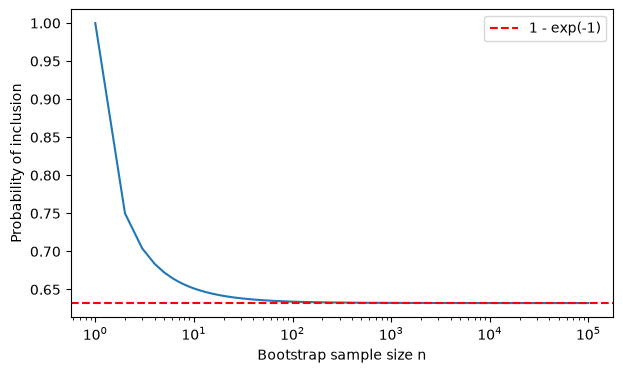

Simulated proportion: 0.6238; theoretical: 0.633968


In [13]:
sizes=np.arange(1,100001)
p=1-(1-1/sizes)**sizes
plt.figure(figsize=(7,4)); plt.plot(sizes,p); plt.xscale('log')
plt.axhline(1-np.exp(-1),ls='--',c='red',label='1 - exp(-1)')
plt.xlabel('Bootstrap sample size n'); plt.ylabel('Probability of inclusion'); plt.legend(); plt.show()
rng=np.random.default_rng(SEED)
store=(rng.integers(1,101,size=(10000,100))==4).any(axis=1)
print(f'Simulated proportion: {store.mean():.4f}; theoretical: {1-.99**100:.6f}')

### ISLR 6.8.4 — Increasing the ridge penalty
The objective is $RSS+\lambda\sum_j\beta_j^2$. Increasing $\lambda$ shrinks the slopes toward zero.

| Part | Choice | Explanation |
|---|---|---|
| (a) Training RSS | iii: increases | Shrinkage moves the fit away from the least-squares minimum; equality is possible in degenerate cases. |
| (b) Test RSS | ii: decreases, then increases | Moderate shrinkage can reduce variance, but excessive shrinkage underfits. This is the usual bias–variance pattern. |
| (c) Variance | iv: decreases | Stronger shrinkage makes the fitted slopes less sensitive to the sample. |
| (d) Squared bias | iii: increases | Stronger shrinkage restricts the fitted relationship. |
| (e) Irreducible error | v: constant | The noise distribution does not depend on the penalty. |

### ISLR 8.4.4 — Trees and partitions
**(a)** One tree producing the left-hand partition first splits at $X_1=1$. Its right region predicts 5. In the left region, split at $X_2=1$: the upper region predicts 15. In the lower region, split at $X_1=0$: the left region predicts 3. Finally split the remaining region at $X_2=0$, giving 10 below and 0 above. The tree is drawn below.

**(b)** Reading the given tree from its root gives these regions:

| Region | Prediction |
|---|---:|
| $X_2<1,\ X_1<1$ | -1.80 |
| $X_2<1,\ X_1\geq1$ | 0.63 |
| $1\leq X_2<2,\ X_1<0$ | -1.06 |
| $1\leq X_2<2,\ X_1\geq0$ | 0.21 |
| $X_2\geq2$ | 2.49 |

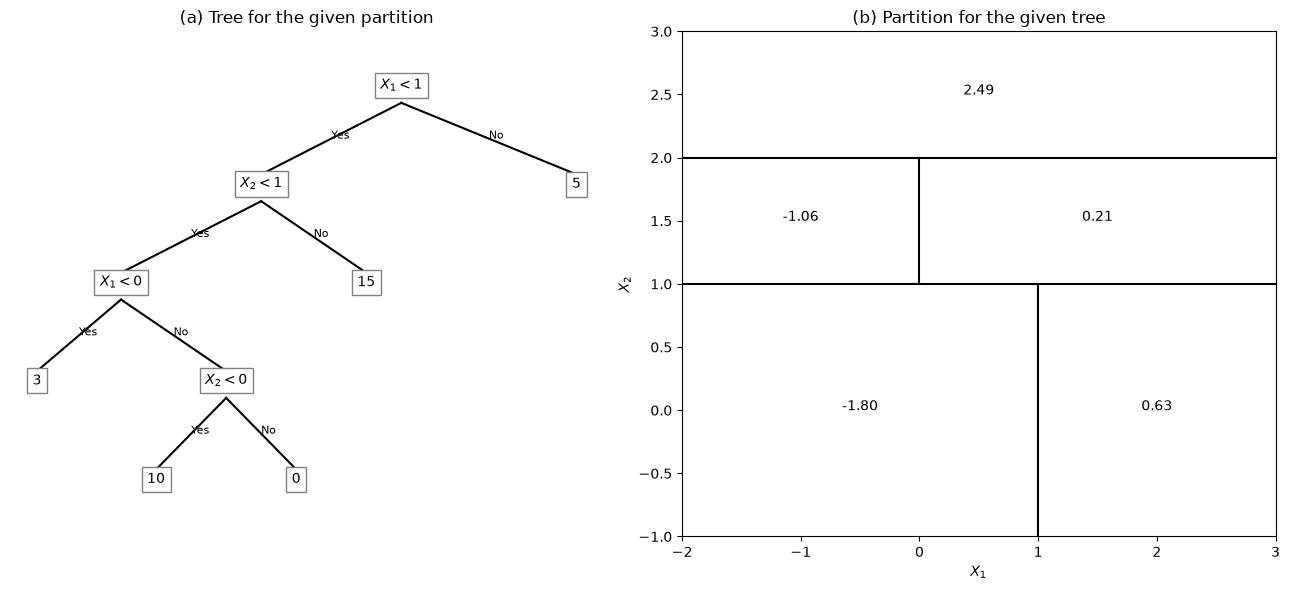

In [14]:
fig,axes=plt.subplots(1,2,figsize=(13,6))
ax=axes[0]; ax.axis('off')
nodes={'a':(.55,.95,'$X_1<1$'),'b':(.35,.73,'$X_2<1$'),'c':(.15,.51,'$X_1<0$'),'d':(.3,.29,'$X_2<0$'),
       'e':(.8,.73,'5'),'f':(.5,.51,'15'),'g':(.03,.29,'3'),'h':(.2,.07,'10'),'i':(.4,.07,'0')}
for key,(xv,yv,label) in nodes.items():ax.text(xv,yv,label,ha='center',bbox=dict(facecolor='white',edgecolor='gray'))
for parent,child,label in [('a','b','Yes'),('a','e','No'),('b','c','Yes'),('b','f','No'),('c','g','Yes'),('c','d','No'),('d','h','Yes'),('d','i','No')]:
    x1,y1,_=nodes[parent];x2,y2,_=nodes[child]
    ax.plot([x1,x2],[y1-.03,y2+.03],color='black');ax.text((x1+x2)/2,(y1+y2)/2,label,fontsize=8)
ax.set_ylim(-.05,1.08); ax.set_title('(a) Tree for the given partition')
ax=axes[1];ax.set(xlim=(-2,3),ylim=(-1,3),xlabel='$X_1$',ylabel='$X_2$')
ax.axhline(1,c='black');ax.axhline(2,c='black');ax.plot([1,1],[-1,1],c='black');ax.plot([0,0],[1,2],c='black')
for xv,yv,label in [(-.5,0,'-1.80'),(2,0,'0.63'),(-1,1.5,'-1.06'),(1.5,1.5,'0.21'),(.5,2.5,'2.49')]:ax.text(xv,yv,label,ha='center')
ax.set_title('(b) Partition for the given tree');plt.tight_layout();plt.show()

### ISLR 9.7.2 — A nonlinear boundary
**(a)** $(1+X_1)^2+(2-X_2)^2=4$ is a circle centered at $(-1,2)$ with radius 2.

**(b)** Values greater than 4 are outside the circle; values at most 4 are inside or on it.

**(c)** The squared distances from the center are 5, 1, 9, and 52 for $(0,0),(-1,1),(2,2),(3,8)$, respectively. Thus the classes are **blue, red, blue, blue**.

**(d)** Expanding and subtracting 4 gives
$$X_1^2+X_2^2+2X_1-4X_2+1=0.$$
This is linear in the transformed features $(X_1,X_1^2,X_2,X_2^2)$, with intercept 1 and coefficients $(2,1,-4,1)$, although it is nonlinear in the original two coordinates.

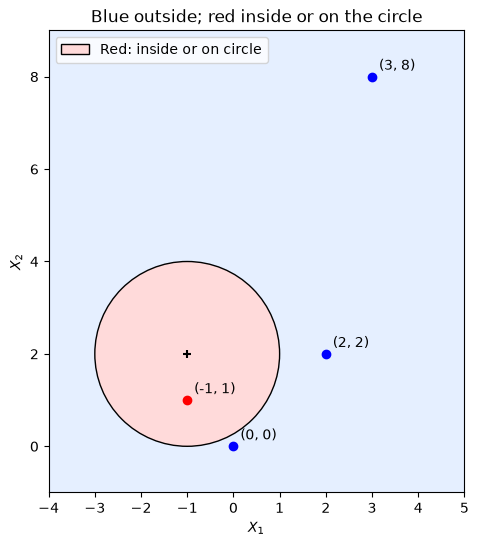

In [15]:
fig,ax=plt.subplots(figsize=(6,6))
ax.set_facecolor('#e5efff')
ax.add_patch(plt.Circle((-1,2),2,facecolor='#ffdada',edgecolor='black',label='Red: inside or on circle'))
for p,col in zip([(0,0),(-1,1),(2,2),(3,8)],['blue','red','blue','blue']):
    ax.scatter(*p,c=col);ax.annotate(str(p),p,xytext=(5,5),textcoords='offset points')
ax.scatter(-1,2,c='black',marker='+')
ax.set(xlim=(-4,5),ylim=(-1,9),xlabel='$X_1$',ylabel='$X_2$',title='Blue outside; red inside or on the circle')
ax.set_aspect('equal');ax.legend();plt.show()